# Quality Control Explorer with 3D Visualization
## Interactive visualization of ANI2X SMILES with 3D coordinates

In [1]:
print('Importing libraries...')
import sys
import os
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
print('Pandas and numpy loaded')

from rdkit import Chem
from rdkit.Chem import Draw, AllChem, Descriptors
print('RDKit loaded')

import ipywidgets as widgets
from IPython.display import display, clear_output, HTML, Image
print('IPywidgets loaded')

try:
    import nglview as nv
    HAS_NGLVIEW = True
    print(f'nglview loaded (version {nv.__version__})')
except ImportError as e:
    nv = None
    HAS_NGLVIEW = False
    print(f'nglview NOT available: {e}')
    print('Install with: pip install nglview')


Importing libraries...
Pandas and numpy loaded
RDKit loaded
IPywidgets loaded


nglview loaded (version 4.0.1)


In [2]:
# Load the quality control CSV data
os.chdir('/Users/jenniferclark/OMSF/OpenFF/DatasetRelease/MetaOMol25_org_smiles')

csv_path = 'ani2x/quality_control/descent-format-ani2x_smiles_quality.csv'
print(f'Loading CSV: {csv_path}...')
df_qc = pd.read_csv(csv_path, low_memory=False)
print(f'Loaded {len(df_qc):,} rows')
print(f'CSV columns: {list(df_qc.columns)}')

Loading CSV: ani2x/quality_control/descent-format-ani2x_smiles_quality.csv...
Loaded 9,323,426 rows
CSV columns: ['index', 'smiles', 'classification', 'issues', 'num_fragments', 'orphaned_h', 'radical', 'charge_imbalance', 'implicit_h']


In [3]:
# Load the huggingface dataset with coordinates

from datasets import load_from_disk
print('Loading huggingface dataset with coordinates...')
hf_path = '/Volumes/JAC_Backup/OpenFF/Meta-OMol25/huggingface_datasets/ani2x/ani2x_smee'
ds_coords = load_from_disk(hf_path)
print(f'Loaded dataset reference: {len(ds_coords):,} entries')
print(f'HF dataset columns: {ds_coords.column_names}')

# DO NOT convert to pandas - keep as HF dataset to avoid loading all into memory
# Access coordinates on-the-fly by index: ds_coords[idx]['coords']
print('Dataset kept as HuggingFace format for on-demand coordinate access')
HAS_COORDS = True


Loading huggingface dataset with coordinates...
Loaded dataset reference: 9,323,426 entries
HF dataset columns: ['smiles', 'coords', 'energy', 'forces']
Dataset kept as HuggingFace format for on-demand coordinate access


In [4]:
# Display statistics
print('\nQuality Control Statistics:')
print('Classification counts:')
print(df_qc['classification'].value_counts())
print(f'\nOrphaned H count: {df_qc["orphaned_h"].sum():,}')
print(f'Multifragment count: {(df_qc["num_fragments"] > 1).sum():,}')

# Prepare filtered datasets - keep the original index for coordinate lookup
orphaned_h_data = df_qc[df_qc['orphaned_h'] == True].reset_index()
multifragment_data = df_qc[df_qc['num_fragments'] > 1].reset_index()

print(f'\nOrphaned H molecules: {len(orphaned_h_data):,}')
print(f'Multifragment molecules: {len(multifragment_data):,}')


Quality Control Statistics:
Classification counts:
classification
OK         7395082
ERROR      1194419
WARNING     733925
Name: count, dtype: int64

Orphaned H count: 1,194,419
Multifragment count: 1,928,344

Orphaned H molecules: 1,194,419
Multifragment molecules: 1,928,344


In [5]:
# ===========================================
# HELPER FUNCTIONS
# ===========================================
# ROOT CAUSE FIX (2026-09-10):
#   Chem.MolFromSmiles(smiles) silently STRIPS the explicit hydrogens written
#   in these atom-mapped SMILES. Dataset row 0 has 21 coordinate atoms but the
#   default parse yields only the 13 heavy atoms, so the atom-count check below
#   failed and this function returned None for EVERY molecule -- which is why
#   no 3D structure ever appeared. nglview was never the problem.
#
#   Fix has two parts:
#     1. removeHs=False        -> keeps the explicit H atoms (correct COUNT)
#     2. renumber by atom map  -> coords are stored in atom-map order, so the
#                                 parsed atoms must be permuted to match (correct ORDER)
#
#   Verified by .agents/scripts/diagnose_mapped_smiles_conformer.py:
#     multifragment rows 25/25, orphaned-H rows 30/30, max bond length 1.92 A
#     (a wrong atom order would produce absurdly long "bonds").
#
# SAFETY POLICY (review round 1):
#   This is a QUALITY CONTROL tool, so it must never silently show a wrong
#   structure. If the atom maps are not a complete 1..N permutation we cannot
#   know which coordinate belongs to which atom, so we REFUSE (return None)
#   rather than render a plausible-looking but wrong geometry.
#
# SANITIZATION POLICY -- HUMAN DECISION, 2026-09-10:
#   Asked whether a SMILES failing RDKit's strict valence check should be
#   refused or shown. Decision: KEEP the relaxed-sanitization fallback and
#   display the molecule, because radicals and odd valences are expected in
#   this dataset and the whole point is to eyeball them. The warning must stay
#   unconditional (a plain print, never _dbg) so the relaxed path is always
#   visible, and cell 7 labels such molecules in the info panel.
#   Do NOT "harden" this into a refusal without asking again.

DEBUG_COORDS = True  # set False to silence the per-molecule debug output


def _dbg(msg):
    """Print a debug line only when DEBUG_COORDS is enabled."""
    if DEBUG_COORDS:
        print(msg)


def parse_mapped_smiles(smiles):
    """Parse an atom-mapped SMILES keeping explicit H, ordered by atom map.

    Returns None if the SMILES cannot be parsed, or if the atom map numbers are
    not a complete 1..N permutation -- in that case the coordinate ordering is
    unknowable and any 3D structure we built would be wrong.

    A molecule that only parses via the relaxed-sanitization retry is flagged
    with the boolean property 'strict_sanitize_failed' so callers can label it.
    """
    params = Chem.SmilesParserParams()
    params.removeHs = False
    mol = Chem.MolFromSmiles(smiles, params)
    relaxed = False

    if mol is None:
        # Retry without sanitization for radicals / odd valences, then do a
        # partial sanitize that skips the properties that would reject them.
        params.sanitize = False
        mol = Chem.MolFromSmiles(smiles, params)
        if mol is None:
            return None
        relaxed = True
        try:
            Chem.SanitizeMol(
                mol,
                sanitizeOps=Chem.SanitizeFlags.SANITIZE_ALL
                ^ Chem.SanitizeFlags.SANITIZE_PROPERTIES,
            )
        except Exception as exc:
            # Unconditional: a QC tool must not hide that sanitization failed.
            print(f'  WARNING: relaxed sanitization also failed ({exc}); '
                  f'molecule is UNSANITIZED and may render incorrectly')
        else:
            print('  WARNING: strict sanitization failed; parsed with '
                  'SANITIZE_PROPERTIES disabled (valence not checked)')

    map_nums = [atom.GetAtomMapNum() for atom in mol.GetAtoms()]
    n = len(map_nums)
    if sorted(map_nums) != list(range(1, n + 1)):
        n_unmapped = sum(1 for m in map_nums if m == 0)
        # Unconditional, not _dbg: this suppresses the 3D structure entirely.
        print(f'  ERROR: atom maps are not a complete 1..{n} permutation '
              f'({n_unmapped} unmapped atom(s)); coordinate order is unknown, '
              f'refusing to build a 3D structure')
        return None

    order = [0] * n
    for idx, map_num in enumerate(map_nums):
        order[map_num - 1] = idx
    ordered = Chem.RenumberAtoms(mol, order)
    ordered.SetBoolProp('strict_sanitize_failed', relaxed)
    return ordered


def coords_list_to_mol_with_conf(smiles, coords_flat):
    """Convert SMILES and flat coords list to RDKit mol with 3D conformer"""
    try:
        mol = parse_mapped_smiles(smiles)
        if mol is None:
            print(f'  ERROR: Could not parse SMILES: {smiles[:50]}...')
            return None

        coords_array = np.array(coords_flat, dtype=np.float64)
        _dbg(f'  DEBUG: Raw coords shape: {coords_array.shape}')

        coords_reshaped = coords_array.reshape(-1, 3)
        _dbg(f'  DEBUG: Reshaped coords: {coords_reshaped.shape} = '
             f'({coords_reshaped.shape[0]} atoms, 3 dims)')

        num_mol_atoms = mol.GetNumAtoms()
        num_coord_atoms = coords_reshaped.shape[0]
        _dbg(f'  DEBUG: Molecule atoms: {num_mol_atoms}, '
             f'Coordinate atoms: {num_coord_atoms}')

        if num_coord_atoms != num_mol_atoms:
            print(f'  ERROR: Mismatch! {num_coord_atoms} coords vs '
                  f'{num_mol_atoms} atoms')
            return None

        conf = Chem.Conformer(num_mol_atoms)
        for i, coord in enumerate(coords_reshaped):
            conf.SetAtomPosition(i, coord.tolist())

        mol.AddConformer(conf, assignId=True)
        _dbg(f'  SUCCESS: Created molecule with {mol.GetNumConformers()} conformer')
        return mol

    except Exception as e:
        print(f'  EXCEPTION in coords_list_to_mol_with_conf: {e}')
        import traceback
        traceback.print_exc()
        return None


def max_bond_length(mol):
    """Longest bonded interatomic distance, a sanity check on atom ordering."""
    if mol is None or mol.GetNumConformers() == 0:
        return None
    conf = mol.GetConformer()
    longest = 0.0
    for bond in mol.GetBonds():
        p = conf.GetAtomPosition(bond.GetBeginAtomIdx())
        q = conf.GetAtomPosition(bond.GetEndAtomIdx())
        d = np.linalg.norm(np.array([p.x, p.y, p.z]) - np.array([q.x, q.y, q.z]))
        longest = max(longest, d)
    return longest


def mol_to_sdf_block(mol):
    """Convert RDKit mol with conformer to SDF string"""
    if mol is None or mol.GetNumConformers() == 0:
        return None
    try:
        return Chem.MolToMolBlock(mol)
    except Exception as e:
        print(f'  Error in mol_to_sdf_block: {e}')
        return None


print('Helper functions defined (explicit-H parsing + atom-map ordering)')


Helper functions defined (explicit-H parsing + atom-map ordering)


In [6]:
# Debug: verify coordinate -> molecule conversion on the first few entries.
# Before the fix this printed "Match: False" for every row because the default
# SMILES parse dropped the explicit hydrogens. It should now print Match: True.
if HAS_COORDS:
    print('Verifying coordinate conversion (on-demand HF dataset access):')
    print(f'Dataset length: {len(ds_coords):,}\n')

    n_ok = 0
    n_test = 3
    for i in range(n_test):
        entry = ds_coords[i]
        smiles = entry['smiles']
        coords = entry['coords']

        print(f'--- Entry {i} ---')
        print(f'SMILES: {smiles[:70]}...')
        print(f'Coords length: {len(coords)} values -> {len(coords) // 3} atoms')

        default_mol = Chem.MolFromSmiles(smiles)
        default_n = default_mol.GetNumAtoms() if default_mol else 0
        print(f'Old parse (MolFromSmiles):     {default_n} atoms')

        mol = coords_list_to_mol_with_conf(smiles, coords)
        if mol is not None:
            longest = max_bond_length(mol)
            print(f'New parse + conformer:        {mol.GetNumAtoms()} atoms')
            print(f'Match: {mol.GetNumAtoms() == len(coords) // 3}')
            print(f'Longest bond: {longest:.2f} A '
                  f'({"sane" if longest <= 2.5 else "SUSPICIOUS - check atom order"})')
            n_ok += 1
        else:
            print('Match: False - conversion returned None')
        print()

    print(f'Converted {n_ok}/{n_test} entries successfully')


Verifying coordinate conversion (on-demand HF dataset access):
Dataset length: 9,323,426

--- Entry 0 ---
SMILES: [H:12][C:5]1=[C:6]([N:17]([C:4](=[N:16]1)[N:15]([H:10])[H:11])[S:20][H...
Coords length: 63 values -> 21 atoms
Old parse (MolFromSmiles):     13 atoms
  DEBUG: Raw coords shape: (63,)
  DEBUG: Reshaped coords: (21, 3) = (21 atoms, 3 dims)
  DEBUG: Molecule atoms: 21, Coordinate atoms: 21
  SUCCESS: Created molecule with 1 conformer
New parse + conformer:        21 atoms
Match: True
Longest bond: 1.76 A (sane)

--- Entry 1 ---
SMILES: [H:15][C:6](=[N:17][S:21][C:5]([H:13])([H:14])[C:4]([H:11])([H:12])[F:...
Coords length: 63 values -> 21 atoms
Old parse (MolFromSmiles):     11 atoms
  DEBUG: Raw coords shape: (63,)
  DEBUG: Reshaped coords: (21, 3) = (21 atoms, 3 dims)
  DEBUG: Molecule atoms: 21, Coordinate atoms: 21
  SUCCESS: Created molecule with 1 conformer
New parse + conformer:        21 atoms
Match: True
Longest bond: 1.82 A (sane)

--- Entry 2 ---
SMILES: [H:11]/[C:

In [7]:
# ===========================================
# WIDGET UPDATE FUNCTION
# ===========================================
# FIX ROUND 2 (2026-09-10) -- addresses the two remaining reports:
#
# A) "still 8 copies of the 2D"
#    ipywidgets.Output works by APPENDING output records; a clear_output that
#    is dropped or races leaves the previous image in place, so renders stack
#    up. Rather than fight that, the panes no longer use Output at all:
#      - 2D  -> widgets.Image, we overwrite .value with new PNG bytes
#      - text-> widgets.HTML,  we overwrite .value with new markup
#      - 3D  -> widgets.Box,   we replace .children (closing the old viewer)
#    Every update OVERWRITES. Accumulation is structurally impossible now.
#    Debug prints from the coordinate conversion are captured with
#    redirect_stdout and folded into the HTML panel, so nothing leaks into the
#    cell's own output area (which WOULD accumulate).
#
# B) "atom ids between the 2d and 3d don't match"
#    render_2d used to call Chem.MolFromSmiles(smiles) -- the default parse,
#    giving 13 heavy atoms in SMILES order -- while the 3D pane used the
#    map-ordered 21-atom molecule. Two different indexings of one structure.
#    Both panes are now built from the SAME parse_mapped_smiles() molecule, so
#    atom index i is the same atom in both, and index i == atom map number i+1.
#    Atom map numbers are zeroed on the drawing copy, because RDKit otherwise
#    renders them as ":12"-style labels that collide with the atom indices.

import io
import html as _html
from contextlib import redirect_stdout

from rdkit.Chem.Draw import rdMolDraw2D

# Pane sizes in pixels. Change these to resize; cell 8 reads them too, so the
# Box and the NGLWidget inside it always agree.
VIEWER_3D_PX = 720
VIEWER_2D_PX = 420

RENDER_COUNT = 0
_is_updating = False

current_mol_3d = None


def render_2d_png(mol, show_indices=True):
    """Return PNG bytes of a 2D depiction of `mol`, preserving its atom order.

    A copy is drawn so the 3D conformer and atom maps on the original survive.
    """
    flat = Chem.Mol(mol)
    flat.RemoveAllConformers()
    # Zero the atom maps or RDKit draws them as labels on every atom.
    for atom in flat.GetAtoms():
        atom.SetAtomMapNum(0)
    AllChem.Compute2DCoords(flat)

    drawer = rdMolDraw2D.MolDraw2DCairo(VIEWER_2D_PX, VIEWER_2D_PX)
    opts = drawer.drawOptions()
    opts.addAtomIndices = show_indices
    opts.explicitMethyl = True
    try:
        rdMolDraw2D.PrepareAndDrawMolecule(drawer, flat)
    except Exception:
        # Molecules that resist kekulization still draw without preparation.
        drawer.DrawMolecule(flat)
    drawer.FinishDrawing()
    return drawer.GetDrawingText()


def build_3d_view(mol_3d, show_indices=True):
    """Return an NGLWidget for `mol_3d`, preserving RDKit atom order.

    The molecule is handed to NGL as an SDF block rather than via show_rdkit's
    PDB conversion, because SDF preserves atom order exactly -- that is what
    makes NGL's atomindex labels agree with the 2D atom indices.
    """
    molblock = Chem.MolToMolBlock(mol_3d, kekulize=False)
    view = nv.NGLWidget(nv.TextStructure(molblock, ext='sdf'))
    view.clear_representations()
    view.add_representation('ball+stick')
    if show_indices:
        view.add_representation('label', labelType='atomindex',
                                color='black', zOffset=1.5,
                                attachment='middle-center')
    view.center()
    view.layout.width = f'{VIEWER_3D_PX}px'
    view.layout.height = f'{VIEWER_3D_PX}px'
    # NGL sizes its canvas from the container, which it measures on load; an
    # explicit handshake avoids a viewer that renders into a stale box.
    view._remote_call('setSize', target='Widget',
                      args=[f'{VIEWER_3D_PX}px', f'{VIEWER_3D_PX}px'])
    return view


def clear_viewer():
    """Empty the 3D pane, closing the outgoing widget so comms do not leak."""
    for child in viewer_box.children:
        try:
            child.close()
        except Exception:
            pass
    viewer_box.children = ()


def _info_html(lines):
    """Wrap plain text lines in escaped <pre> markup for the HTML panel."""
    body = _html.escape('\n'.join(lines))
    return (f'<pre style="margin:0;font-size:12px;line-height:1.35;'
            f'white-space:pre-wrap;word-break:break-all">{body}</pre>')


def update_display(*args):
    """Update the molecule display. 2D always; 3D beside it when toggled on."""
    global RENDER_COUNT, _is_updating, current_mol_3d

    # Collapse cascaded events (max/value changes) into a single render.
    if _is_updating:
        return
    _is_updating = True

    lines = []
    try:
        RENDER_COUNT += 1

        clear_viewer()

        selected_category = category_dropdown.value
        current_data = (orphaned_h_data
                        if selected_category == 'num_orphaned_h'
                        else multifragment_data)

        idx = current_idx
        if idx >= len(current_data):
            lines.append(f'ERROR: Index {idx} out of range '
                         f'({len(current_data)} rows in this category)')
            return

        row_qc = current_data.iloc[idx]
        original_index = int(row_qc['index'])
        smiles = row_qc['smiles']
        show_ids = atom_ids_toggle.value

        lines.append(f'[render #{RENDER_COUNT}]  '
                     f'(increases by exactly 1 per interaction)')
        lines.append(f'Category: {selected_category}')
        lines.append(f'Sample: {idx}/{len(current_data) - 1}')
        lines.append(f'CSV index: {original_index}')
        lines.append(f'SMILES: {smiles}')
        lines.append(f'Classification: {row_qc["classification"]}')
        lines.append(f'Issues: {row_qc["issues"]}')
        lines.append(f'Fragments: {row_qc["num_fragments"]}')

        current_mol_3d = None

        # --- ONE molecule drives BOTH panes, so atom indices agree ---
        buf = io.StringIO()
        with redirect_stdout(buf):
            mol = parse_mapped_smiles(smiles)
        parse_msgs = buf.getvalue().strip()
        if parse_msgs:
            lines.append(parse_msgs)

        if mol is None:
            lines.append('\nERROR: Could not build a trustworthy molecule '
                         'from this SMILES - nothing displayed (see above).')
            img_widget.value = b''
            return

        if mol.GetBoolProp('strict_sanitize_failed'):
            lines.append('NOTE: this molecule required relaxed sanitization; '
                         'treat the depiction with caution.')

        lines.append(f'Atoms (explicit H, atom-map order): {mol.GetNumAtoms()}')
        if show_ids:
            lines.append('Atom labels are 0-based indices, identical in the '
                         '2D and 3D panes (atom map number = index + 1).')

        img_widget.value = render_2d_png(mol, show_indices=show_ids)

        # --- 3D pane (only when toggled on; no silent fallback to 2D) ---
        if not view_3d_toggle.value:
            return

        lines.append('\n=== 3D MODE ACTIVE ===')

        if not HAS_NGLVIEW:
            lines.append('ERROR: nglview not available! pip install nglview')
            return
        if not HAS_COORDS or ds_coords is None:
            lines.append('ERROR: Coordinates dataset not loaded!')
            return
        if original_index >= len(ds_coords):
            lines.append(f'ERROR: Index {original_index} out of range '
                         f'(dataset has {len(ds_coords)})')
            return

        try:
            coords = ds_coords[original_index]['coords']
            lines.append(f'Retrieved {len(coords)} coordinate values')
        except Exception as e:
            lines.append(f'ERROR fetching coords: {e}')
            return

        buf = io.StringIO()
        with redirect_stdout(buf):
            mol_3d = coords_list_to_mol_with_conf(smiles, coords)
        debug_text = buf.getvalue().strip()
        if debug_text:
            lines.append(debug_text)

        if mol_3d is None:
            lines.append('\nERROR: coords_list_to_mol_with_conf returned None!')
            return

        current_mol_3d = mol_3d
        longest = max_bond_length(mol_3d)
        lines.append(f'Longest bond: {longest:.2f} A '
                     f'({"sane" if longest <= 2.5 else "SUSPICIOUS atom order"})')

        try:
            view = build_3d_view(mol_3d, show_indices=show_ids)
        except Exception as e:
            import traceback
            lines.append(f'ERROR creating nglview: {e}')
            lines.append(traceback.format_exc())
            return

        viewer_box.children = (view,)

    finally:
        # Single assignment per render - the HTML panel cannot accumulate.
        info_html.value = _info_html(lines)
        _is_updating = False


print(f'Update function defined (3D pane {VIEWER_3D_PX}px, '
      f'2D pane {VIEWER_2D_PX}px)')

Update function defined (3D pane 720px, 2D pane 420px)


In [8]:
# ===========================================
# CREATE WIDGETS AND DISPLAY INTERFACE
# ===========================================
# Re-running this cell is SAFE. It builds brand-new widget objects, so handlers
# cannot accumulate on them. The unobserve_all() block below exists for a
# different reason: widget objects from a PREVIOUS run of this cell stay alive
# in the frontend (in this cell's old output area and in the kernel's widget
# registry), and their handlers would still fire into update_display if you
# interacted with those stale views. Detaching them keeps exactly one live
# interface driving the panes.
#
# The display panes are overwrite-only widgets (Image / HTML / Box) rather than
# Output widgets, because Output APPENDS and was stacking up duplicate 2D
# depictions. See Cell 7 for the full explanation.
#
# Pane sizes come from VIEWER_3D_PX / VIEWER_2D_PX in Cell 7 so the Box and the
# NGLWidget it holds can never disagree. Resize by editing those two numbers.

print('Creating widgets...')

# Detach handlers from any widgets left over from a previous run of this cell.
for _name in ('category_dropdown', 'prev_button', 'next_button', 'view_3d_toggle',
              'atom_ids_toggle'):
    _old = globals().get(_name)
    if _old is not None:
        try:
            _old.unobserve_all()
        except Exception:
            pass

# Close stale panes so their frontend views stop rendering old content.
for _name in ('info_html', 'img_widget', 'viewer_box'):
    _old = globals().get(_name)
    if _old is not None:
        try:
            _old.close()
        except Exception:
            pass

category_dropdown = widgets.Dropdown(
    options=[('Orphaned Hydrogen', 'num_orphaned_h'),
             ('Multifragment', 'num_multifragment')],
    value='num_orphaned_h',
    description='Category:',
    style={'description_width': 'initial'}
)

# Navigation state
current_idx = 0

# Arrow buttons and counter
prev_button = widgets.Button(
    description='◀ Prev',
    button_style='info',
    tooltip='Previous molecule'
)

counter_display = widgets.HTML(
    value='<b>0 / 0</b>',
    layout=widgets.Layout(min_width='80px', text_align='center')
)

next_button = widgets.Button(
    description='Next ▶',
    button_style='info',
    tooltip='Next molecule'
)

view_3d_toggle = widgets.Checkbox(
    value=False,
    description='Show 3D Structure',
    style={'description_width': 'initial'}
)

atom_ids_toggle = widgets.Checkbox(
    value=True,
    description='Show atom indices',
    style={'description_width': 'initial'}
)

export_button = widgets.Button(
    description='Export to SDF',
    button_style='info',
    tooltip='Export current molecule with 3D coordinates to SDF file'
)

# Overwrite-only display panes, sized from the Cell 7 constants.
info_html = widgets.HTML(value='')
img_widget = widgets.Image(
    format='png',
    layout=widgets.Layout(width=f'{VIEWER_2D_PX}px',
                          height=f'{VIEWER_2D_PX}px',
                          border='1px solid #ddd'))
viewer_box = widgets.Box(
    layout=widgets.Layout(width=f'{VIEWER_3D_PX + 10}px',
                          min_height=f'{VIEWER_3D_PX + 10}px',
                          border='1px solid #ddd'))

print('Widgets created')


def update_counter():
    """Update the counter display with current index."""
    selected_category = category_dropdown.value
    current_data = (orphaned_h_data
                    if selected_category == 'num_orphaned_h'
                    else multifragment_data)
    total = len(current_data)
    counter_display.value = f'<b>{current_idx} / {total - 1}</b>'


def on_prev(button):
    """Go to previous molecule."""
    global current_idx
    selected_category = category_dropdown.value
    current_data = (orphaned_h_data
                    if selected_category == 'num_orphaned_h'
                    else multifragment_data)
    
    if current_idx > 0:
        current_idx -= 1
        update_counter()
        update_display()


def on_next(button):
    """Go to next molecule."""
    global current_idx
    selected_category = category_dropdown.value
    current_data = (orphaned_h_data
                    if selected_category == 'num_orphaned_h'
                    else multifragment_data)
    
    if current_idx < len(current_data) - 1:
        current_idx += 1
        update_counter()
        update_display()


def on_category_change(change):
    """Reset index when category changes."""
    global current_idx
    current_idx = 0
    update_counter()
    update_display()


def on_export(button):
    """Write the current 3D molecule to an SDF file."""
    try:
        if current_mol_3d is None:
            info_html.value += _info_html(
                ['', 'No 3D molecule available - '
                     'enable "Show 3D Structure" first'])
            return

        output_dir = 'ani2x/quality_control/exported_molecules'
        os.makedirs(output_dir, exist_ok=True)

        filename = (f'{output_dir}/molecule_'
                    f'{category_dropdown.value}_{current_idx}.sdf')

        writer = Chem.SDWriter(filename)
        writer.write(current_mol_3d)
        writer.close()

        info_html.value += _info_html(['', f'Exported: {filename}'])
    except Exception as e:
        info_html.value += _info_html(['', f'Export failed: {e}'])


category_dropdown.observe(on_category_change, names='value')
prev_button.on_click(on_prev)
next_button.on_click(on_next)
view_3d_toggle.observe(update_display, names='value')
atom_ids_toggle.observe(update_display, names='value')
export_button.on_click(on_export)

print('Handlers attached (stale widgets detached first)')

# Navigation controls with counter
nav_controls = widgets.HBox([prev_button, counter_display, next_button],
                            layout=widgets.Layout(align_items='center', width='100%'))

controls = widgets.HBox([
    widgets.VBox([category_dropdown, nav_controls]),
    widgets.VBox([view_3d_toggle, atom_ids_toggle, export_button]),
])

# 2D and 3D sit side by side; the panes wrap to one column on a narrow window
# so the larger 3D viewer never pushes the 2D depiction off screen.
panes = widgets.HBox([img_widget, viewer_box],
                     layout=widgets.Layout(flex_flow='row wrap',
                                           align_items='flex-start'))

display(widgets.VBox([controls, info_html, panes]))

update_counter()
update_display()

print(f'\nInterface ready. 3D viewer is {VIEWER_3D_PX}px. Atom indices are '
      f'0-based and identical in both panes (atom map number = index + 1).')

Creating widgets...
Widgets created
Handlers attached (stale widgets detached first)



Interface ready. 3D viewer is 720px. Atom indices are 0-based and identical in both panes (atom map number = index + 1).


## Interactive Molecule Browser
### Browse and visualize molecules with quality control issues

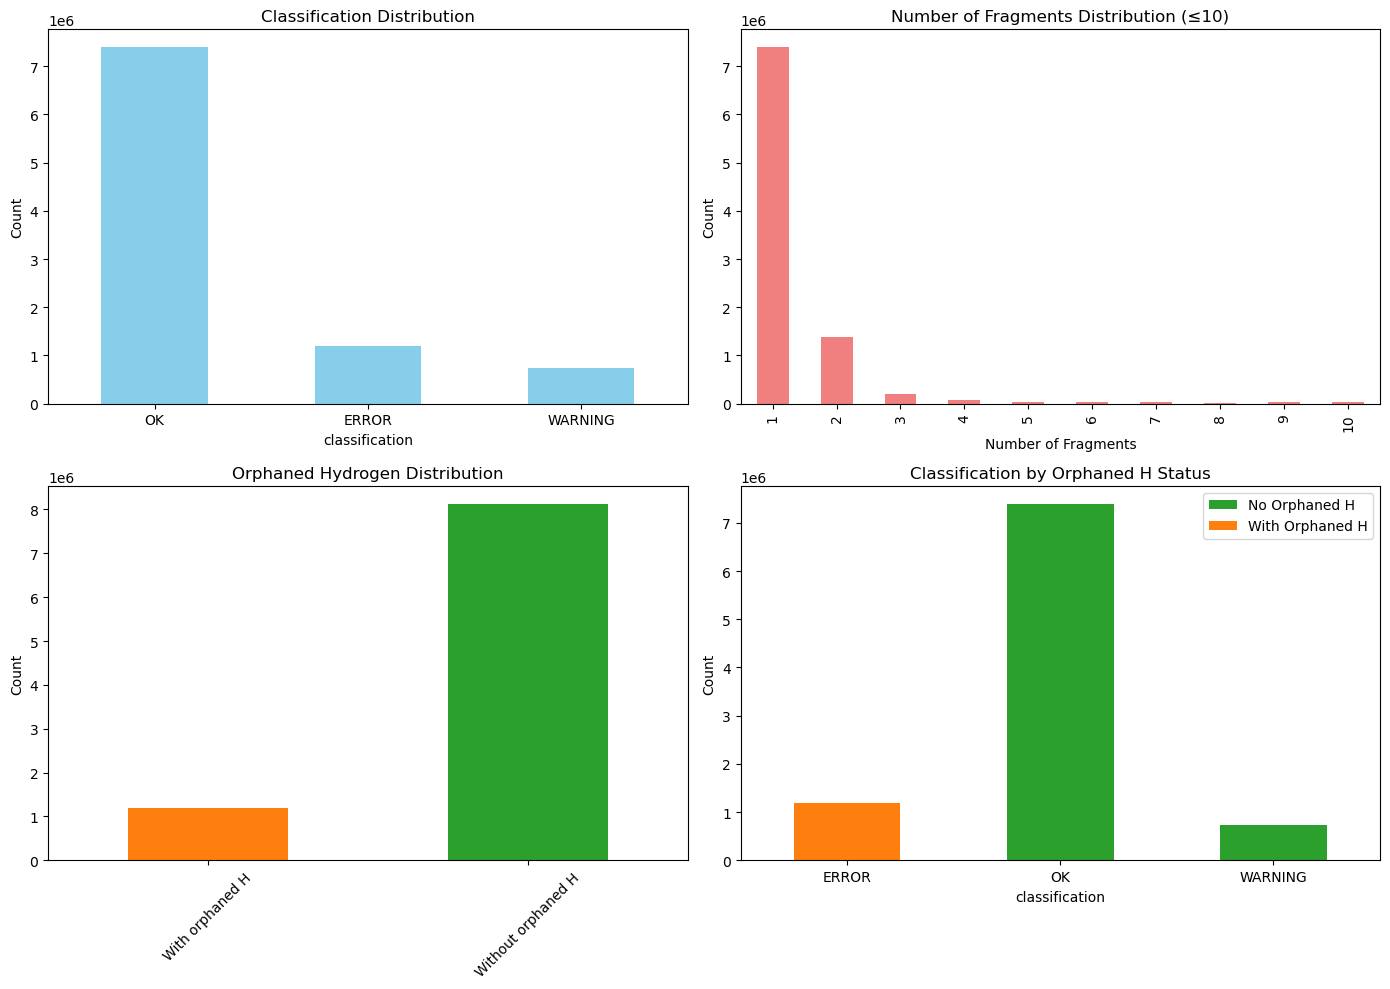


Summary Statistics:
Total entries: 9,323,426
Entries with orphaned H: 1,194,419 (12.8%)
Multifragment entries: 1,928,344 (20.7%)
Fragment count range: 1 to 17
Average fragments: 1.457

Coordinates available: 9,323,426 entries (on-demand access)


In [9]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Classification distribution
df_qc['classification'].value_counts().plot(kind='bar', ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Classification Distribution')
axes[0, 0].set_ylabel('Count')
axes[0, 0].tick_params(axis='x', rotation=0)

# Fragment distribution
fragment_counts = df_qc['num_fragments'].value_counts().sort_index()
fragment_counts[fragment_counts.index <= 10].plot(kind='bar', ax=axes[0, 1], color='lightcoral')
axes[0, 1].set_title('Number of Fragments Distribution (≤10)')
axes[0, 1].set_ylabel('Count')
axes[0, 1].set_xlabel('Number of Fragments')

# Orphaned H vs Other
orphaned_counts = pd.Series({
    'With orphaned H': df_qc['orphaned_h'].sum(),
    'Without orphaned H': (~df_qc['orphaned_h']).sum()
})
orphaned_counts.plot(kind='bar', ax=axes[1, 0], color=['#ff7f0e', '#2ca02c'])
axes[1, 0].set_title('Orphaned Hydrogen Distribution')
axes[1, 0].set_ylabel('Count')
axes[1, 0].tick_params(axis='x', rotation=45)

# Classification breakdown
class_breakdown = df_qc.groupby(['classification', 'orphaned_h']).size().unstack(fill_value=0)
class_breakdown.plot(kind='bar', ax=axes[1, 1], stacked=True, color=['#2ca02c', '#ff7f0e'])
axes[1, 1].set_title('Classification by Orphaned H Status')
axes[1, 1].set_ylabel('Count')
axes[1, 1].legend(['No Orphaned H', 'With Orphaned H'])
axes[1, 1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

print('\nSummary Statistics:')
print(f'Total entries: {len(df_qc):,}')
print(f'Entries with orphaned H: {df_qc["orphaned_h"].sum():,} ({100*df_qc["orphaned_h"].sum()/len(df_qc):.1f}%)')
print(f'Multifragment entries: {(df_qc["num_fragments"] > 1).sum():,} ({100*(df_qc["num_fragments"] > 1).sum()/len(df_qc):.1f}%)')
print(f'Fragment count range: {df_qc["num_fragments"].min():.0f} to {df_qc["num_fragments"].max():.0f}')
print(f'Average fragments: {df_qc["num_fragments"].mean():.3f}')
if HAS_COORDS:
    print(f'\nCoordinates available: {len(ds_coords):,} entries (on-demand access)')

In [10]:
from collections import defaultdict
from rdkit.Chem import GetSSSR

print('Analyzing distances from orphaned H+ to closest atoms in other fragments...')

# defaultdict: element_symbol -> list of distances
h_distances_by_element = defaultdict(list)

processed = 0
errors = 0
h_plus_found = 0

for idx in range(len(orphaned_h_data)):
    try:
        row = orphaned_h_data.iloc[idx]
        original_index = int(row['index'])
        smiles = row['smiles']
        
        # Get molecule structure
        mol = parse_mapped_smiles(smiles)
        if mol is None:
            errors += 1
            continue
        
        # Get coordinates
        if original_index >= len(ds_coords):
            errors += 1
            continue
        
        coords = ds_coords[original_index]['coords']
        coords_array = np.array(coords, dtype=np.float64).reshape(-1, 3)
        
        if coords_array.shape[0] != mol.GetNumAtoms():
            errors += 1
            continue
        
        # Split into fragments
        fragments = Chem.GetMolFrags(mol, asMols=False, sanitizeFrags=False)
        
        # Find orphaned H+ fragments (single H atoms with positive charge)
        for frag_atom_indices in fragments:
            if len(frag_atom_indices) != 1:
                continue
            
            atom_idx = frag_atom_indices[0]
            atom = mol.GetAtomWithIdx(atom_idx)
            
            # Check if it's an H with positive charge
            if atom.GetSymbol() != 'H' or atom.GetFormalCharge() != 1:
                continue
            
            h_plus_found += 1
            h_pos = coords_array[atom_idx]
            closest_dist = float('inf')
            closest_element = None
            
            # Find closest atom from other fragments
            for other_frag_atom_indices in fragments:
                if other_frag_atom_indices == frag_atom_indices:
                    continue  # Skip this fragment
                
                for other_idx in other_frag_atom_indices:
                    other_atom = mol.GetAtomWithIdx(other_idx)
                    other_pos = coords_array[other_idx]
                    dist = np.linalg.norm(h_pos - other_pos)
                    
                    if dist < closest_dist:
                        closest_dist = dist
                        closest_element = other_atom.GetSymbol()
            
            if closest_element is not None:
                h_distances_by_element[closest_element].append(closest_dist)
        
        processed += 1
        if processed % 10000 == 0:
            print(f'  Processed {processed:,} molecules, found {h_plus_found:,} H+ ions...')
    
    except Exception as e:
        errors += 1
        continue

print(f'\nProcessed {processed:,} orphaned H molecules ({errors:,} errors)')
print(f'Found {h_plus_found:,} orphaned H+ ions total')
print(f'\nElement summary (closest atom to H+ in other fragments):')
for element in sorted(h_distances_by_element.keys()):
    distances = h_distances_by_element[element]
    print(f'  {element}: {len(distances):,} H+ ions, '
          f'mean distance: {np.mean(distances):.3f} Å, '
          f'range: {np.min(distances):.3f}-{np.max(distances):.3f} Å')

Analyzing distances from orphaned H+ to closest atoms in other fragments...
  Processed 10,000 molecules, found 12,873 H+ ions...
  Processed 20,000 molecules, found 25,125 H+ ions...
  Processed 30,000 molecules, found 37,602 H+ ions...
  Processed 40,000 molecules, found 50,476 H+ ions...
  Processed 50,000 molecules, found 63,202 H+ ions...
  Processed 60,000 molecules, found 75,874 H+ ions...
  Processed 70,000 molecules, found 87,337 H+ ions...
  Processed 80,000 molecules, found 99,412 H+ ions...
  Processed 90,000 molecules, found 113,253 H+ ions...
  Processed 100,000 molecules, found 127,128 H+ ions...
  Processed 110,000 molecules, found 139,857 H+ ions...
  Processed 120,000 molecules, found 152,865 H+ ions...
  Processed 130,000 molecules, found 165,162 H+ ions...
  Processed 140,000 molecules, found 177,649 H+ ions...
  Processed 150,000 molecules, found 190,426 H+ ions...
  Processed 160,000 molecules, found 202,697 H+ ions...
  Processed 170,000 molecules, found 214,547 

[16:42:14] Conflicting single bond directions around double bond at index 1.
[16:42:14]   BondStereo set to STEREONONE and single bond directions set to NONE.


  Processed 460,000 molecules, found 582,196 H+ ions...
  Processed 470,000 molecules, found 595,847 H+ ions...
  Processed 480,000 molecules, found 608,576 H+ ions...
  Processed 490,000 molecules, found 621,646 H+ ions...


[16:42:32] Conflicting single bond directions around double bond at index 5.
[16:42:32]   BondStereo set to STEREONONE and single bond directions set to NONE.


  Processed 500,000 molecules, found 634,371 H+ ions...
  Processed 510,000 molecules, found 647,507 H+ ions...


...

  Processed 780,000 molecules, found 985,700 H+ ions...
  Processed 790,000 molecules, found 998,379 H+ ions...
  Processed 800,000 molecules, found 1,011,690 H+ ions...
  Processed 810,000 molecules, found 1,023,970 H+ ions...
  Processed 820,000 molecules, found 1,036,933 H+ ions...
  Processed 830,000 molecules, found 1,050,102 H+ ions...
  Processed 840,000 molecules, found 1,062,548 H+ ions...
  Processed 850,000 molecules, found 1,075,371 H+ ions...
  Processed 860,000 molecules, found 1,088,158 H+ ions...
  Processed 870,000 molecules, found 1,100,692 H+ ions...
  Processed 880,000 molecules, found 1,113,286 H+ ions...
  Processed 890,000 molecules, found 1,125,885 H+ ions...
  Processed 900,000 molecules, found 1,138,513 H+ ions...
  Processed 910,000 molecules, found 1,151,904 H+ ions...
  Processed 920,000 molecules, found 1,165,157 H+ ions...
  Processed 930,000 molecules, found 1,177,716 H+ ions...
  Processed 940,000 molecules, found 1,190,222 H+ ions...
  Processed 950,00

[16:48:30] Conflicting single bond directions around double bond at index 5.
[16:48:30]   BondStereo set to STEREONONE and single bond directions set to NONE.
[16:48:31] Conflicting single bond directions around double bond at index 5.
[16:48:31]   BondStereo set to STEREONONE and single bond directions set to NONE.


  Processed 1,130,000 molecules, found 1,438,788 H+ ions...
  Processed 1,140,000 molecules, found 1,452,525 H+ ions...
  Processed 1,150,000 molecules, found 1,465,599 H+ ions...
  Processed 1,160,000 molecules, found 1,479,281 H+ ions...


[16:49:12] Conflicting single bond directions around double bond at index 5.
[16:49:12]   BondStereo set to STEREONONE and single bond directions set to NONE.


  Processed 1,170,000 molecules, found 1,491,088 H+ ions...
  Processed 1,180,000 molecules, found 1,503,912 H+ ions...
  Processed 1,190,000 molecules, found 1,516,772 H+ ions...

Processed 1,194,419 orphaned H molecules (0 errors)
Found 1,522,728 orphaned H+ ions total

Element summary (closest atom to H+ in other fragments):
  C: 819,334 H+ ions, mean distance: 1.409 Å, range: 1.324-2.794 Å
  Cl: 408 H+ ions, mean distance: 2.199 Å, range: 0.861-4.724 Å
  F: 887 H+ ions, mean distance: 1.549 Å, range: 1.130-3.337 Å
  H: 22,427 H+ ions, mean distance: 1.466 Å, range: 0.832-4.321 Å
  N: 293,731 H+ ions, mean distance: 1.395 Å, range: 1.271-2.786 Å
  O: 271,611 H+ ions, mean distance: 1.382 Å, range: 1.080-4.527 Å
  S: 114,330 H+ ions, mean distance: 1.801 Å, range: 0.875-4.578 Å


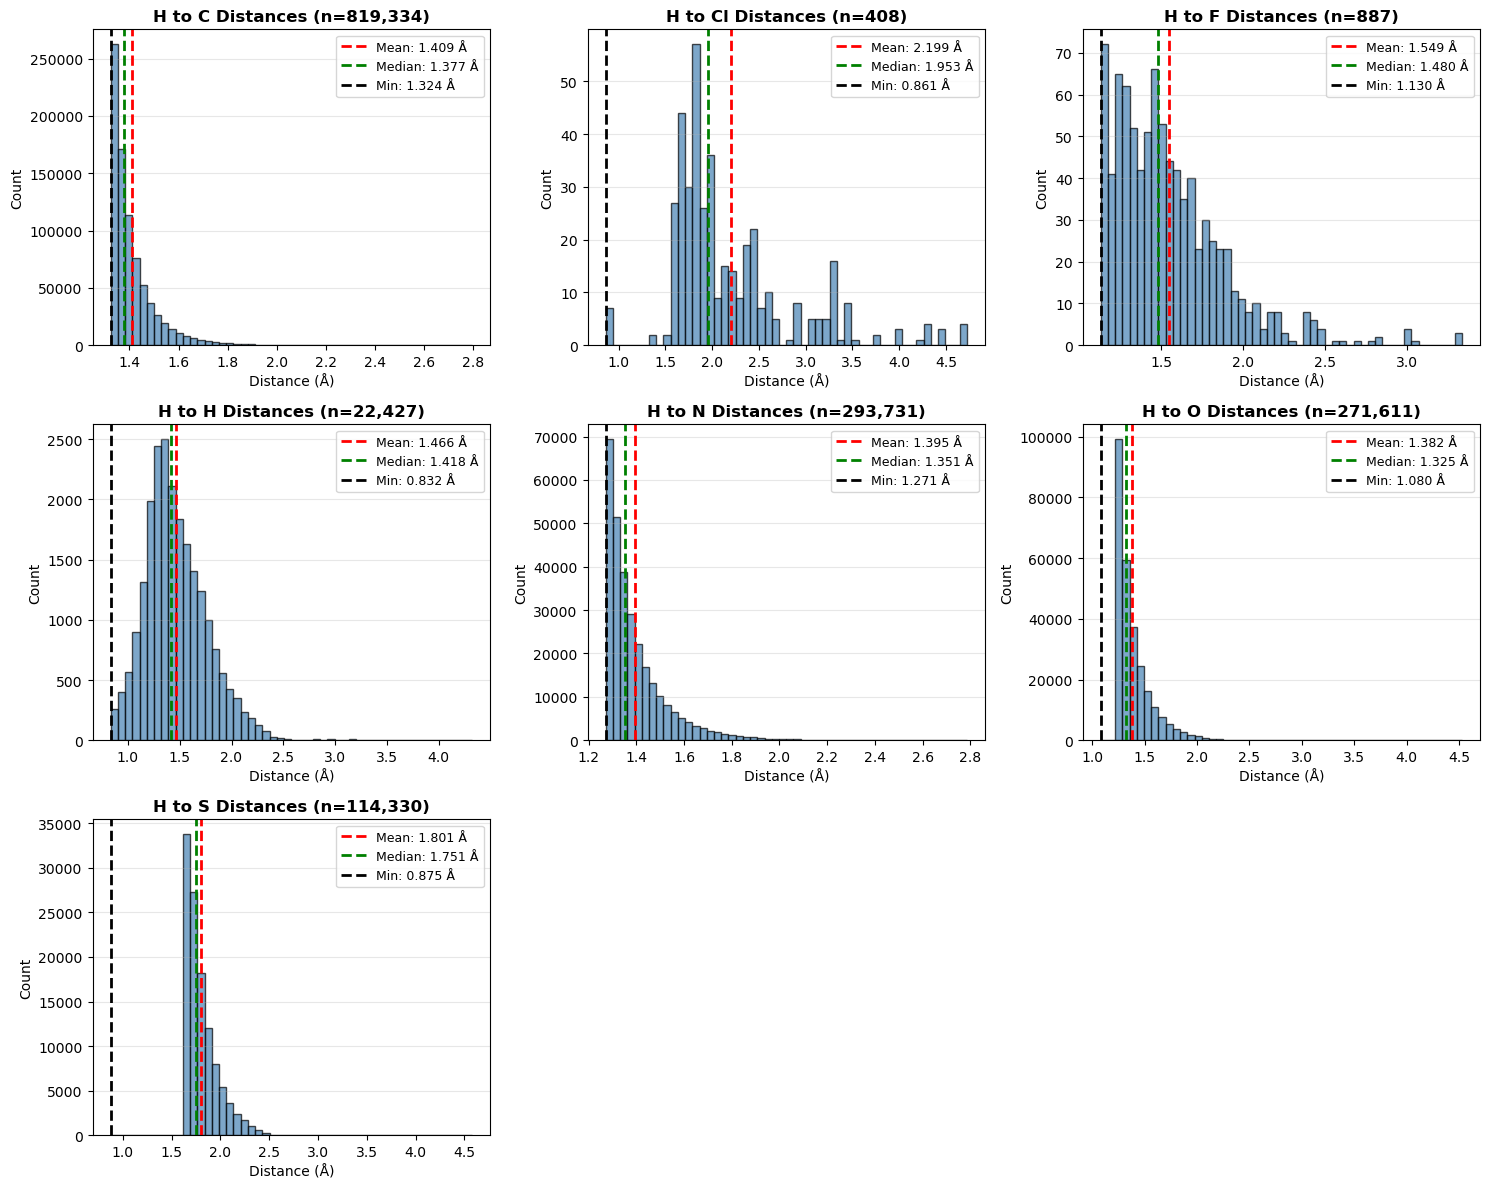


Created histograms for 7 elements


In [13]:
# Create histograms for each element
elements = sorted(h_distances_by_element.keys())
n_elements = len(elements)

# Calculate grid size
n_cols = 3
n_rows = (n_elements + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()  # Flatten for easier indexing

for i, element in enumerate(elements):
    ax = axes[i]
    distances = h_distances_by_element[element]
    
    ax.hist(distances, bins=50, color='steelblue', edgecolor='black', alpha=0.7)
    ax.set_title(f'H to {element} Distances (n={len(distances):,})', fontsize=12, fontweight='bold')
    ax.set_xlabel('Distance (Å)')
    ax.set_ylabel('Count')
    ax.grid(axis='y', alpha=0.3)
    
    # Add statistics text
    mean_dist = np.mean(distances)
    median_dist = np.median(distances)
    min_dist = np.min(distances)
    ax.axvline(mean_dist, color='red', linestyle='--', linewidth=2, label=f'Mean: {mean_dist:.3f} Å')
    ax.axvline(median_dist, color='green', linestyle='--', linewidth=2, label=f'Median: {median_dist:.3f} Å')
    ax.axvline(min_dist, color='k', linestyle='--', linewidth=2, label=f'Min: {min_dist:.3f} Å')
    ax.legend(fontsize=9)

# Hide unused subplots
for i in range(n_elements, len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()

print(f'\nCreated histograms for {n_elements} elements')